# Isolation Forest

An isolation forest gives a high anomaly score to observations that are separated with few random cuts.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Novelty model

Only ordinary observations enter the fit.

In [2]:
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from gallery.unsupervised import anomaly_data, anomaly_report

## Fresh observations

Three shifted groups are injected into an independent test sample.

In [3]:
X_train, X_test, y_test = anomaly_data()
model = IsolationForest(n_estimators=110, contamination=0.05, random_state=17).fit(X_train)

## Detection quality

The boundary uses the fitted threshold. Ranking metrics use continuous scores.

ROC AUC: 0.965 | Average precision: 0.730 | Prevalence: 0.135
Precision: 0.610 | Recall: 1.000 | F1: 0.758
Rows = actual inlier/outlier, columns = predicted inlier/outlier
[[207  23]
 [  0  36]]


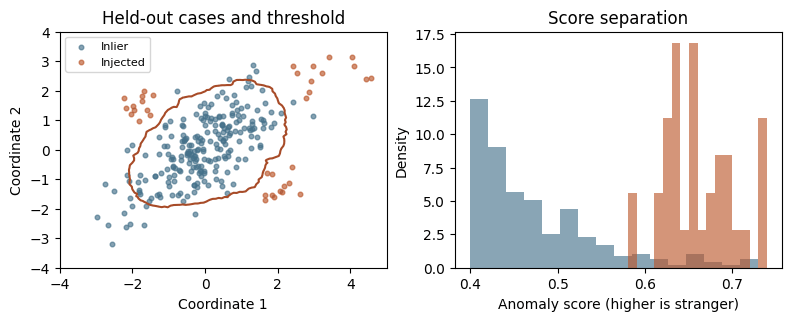

In [4]:
anomaly_report(model, X_test, y_test)
plt.show()

## Reading the result

The injected group near the ordinary cloud is deliberately ambiguous. Precision and recall depend on the operating threshold as well as separation.

## References

[scikit-learn, IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html)

[scikit-learn, novelty and outlier detection](https://scikit-learn.org/stable/modules/outlier_detection.html)

[Dataset generators and evaluation](../../../gallery/unsupervised.py)